# Statistiques de auair

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/EmbeddedComputervision/blob/main/notebooks/auair/auair_stats.ipynb)

Présentation et analyse statistique du jeu, lues du point de vue de Tiny-YOLO et de la
cible embarquée (entrée 416, grilles 13×13 et 26×26, 256 emplacements de `yolo_post`,
INT8). Tâches : T18.1, T18.8, [T16.4](../../docs/tasks/M16-presentation-jeux.md) ; jalon : [M16](../../docs/tasks/M16-presentation-jeux.md) ;
synthèse : [stats-jeux.md](../../docs/tasks/stats-jeux.md). Autres notebooks du jeu :
[tiny-yolov2-voc_infer](tiny-yolov2-voc_infer.ipynb), [tiny-yolov3-coco_infer](tiny-yolov3-coco_infer.ipynb), [tiny-yolov3-auair_infer](tiny-yolov3-auair_infer.ipynb), [tiny-yolov3-auair_train](tiny-yolov3-auair_train.ipynb), [tiny-yolov3-auair_sweep](tiny-yolov3-auair_sweep.ipynb).

Palier : annotations **R** (split entier), pixels **M** (`SAMPLE = 200`
images par partie). Prérequis : données `data/auair/annotations.json` — tools/get_datasets.sh auair (inscription : source affichée). Ni poids ni GPU.

Question propre : Que reste-t-il des objets d'une trame 1920×1080 réduite à 416, classe par classe ? (renvoi : T18.1).

| | |
|---|---|
| source | https://bozcani.github.io/auairdataset |
| version | 2019 (annotations.json, 8 vidéos) ; découpage maison par vidéo |
| licence | CC BY-NC-SA 2.0 (champ `licenses` du JSON) |
| capteur | drone Parrot Bebop 2, caméra couleur, Aarhus (Danemark), vues obliques et verticales, altitude et attitude par trame |
| résolution typique | 1920×1080 |
| officiel `train` | 27880 images, — objets |
| officiel `val` | 4943 images, — objets |
| chargeur | pas de découpage officiel : val = 3 vidéos entières (`AUAIR_VAL`) |
| chargeur | clé `image_width:` (sic) et noms `_xx_` du JSON tolérés |
| chargeur | boîtes vides après rognage retirées (54) |

Aucun calcul ici : `tools/data_stats.py` calcule (`stats.json`, `stats.md`, galerie),
`tools/figures/donnees.py` trace ; chaque étape affiche la commande. Sorties dans
`build/notebooks/auair/stats/`, jamais dans `results/`. Notebook généré par `python -m tools.notebooks`
(`make notebooks`) : modifier `tools/notebooks/gabarits.py`, pas ce fichier.

## Paramètres

In [3]:
DATASET   = 'auair'  # clé de DATASETS
SPLITS    = None  # liste de splits ; None : splits train puis test du jeu
SIZE      = None  # S ou 'LxH' ; None : entrée de la cfg du jeu (416 sinon)
RESIZE    = 'letterbox'  # letterbox | stretch (grandeurs vues par le réseau)
SAMPLE    = 200  # images lues pour les pixels, par partie ; 0 : aucune
GALLERY   = 8  # images de la galerie par split
SEED      = 0  # tirage des images (pixels, galerie, nuages)
NET       = 'build/m11/cfg/tiny-yolov3-auair.cfg'  # cfg dont les ancres et grilles servent aux collisions
DEVICE    = 'cpu'  # noyau CPU : rien ne tourne sur GPU
DATA_ROOT = None  # racine du jeu ; None : data/<jeu> (Colab : dossier Drive)
DRIVE_DIR = '/content/drive/MyDrive/EmbeddedCV'  # Colab : archives data/<jeu>.tar ; None : pas de Drive
OUT       = 'build/notebooks/auair/stats'  # sorties du notebook
REPO_URL  = 'https://github.com/lrivals/EmbeddedComputervision.git'  # Colab : dépôt cloné
REV       = 'main'  # Colab : révision

## Environnement

Local : rien n'est installé ni téléchargé, la cellule vérifie les prérequis et
s'arrête avec la commande à lancer. Colab : clone du dépôt, installation, CuPy si
`DEVICE = "gpu"`, poids, puis données par `colab.prepare_data` (archive
`<DRIVE_DIR>/data/<jeu>.tar` ou téléchargement direct ; ExDark et FLIR : archive
seulement, faite sur le PC par `tools/get_datasets.sh pack <jeu>`).

In [4]:
import os
import subprocess
import sys
from pathlib import Path

COLAB = "google.colab" in sys.modules


def repo_root():
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "tools" / "notebooks" / "commandes.py").exists():
            return d
    return None


ROOT = repo_root()
if COLAB:
    if ROOT is None:
        ROOT = Path("/content/EmbeddedComputervision")
        if not ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    # Clone d'une session précédente : remis à REV (notebook et code du même commit).
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "FETCH_HEAD"], check=True)
    for m in [m for m in sys.modules if m.split(".")[0] in ("tools", "yolo")]:
        del sys.modules[m]  # modules importés avant la mise à jour
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}/python[data,plots]"], check=True)
    if DEVICE == "gpu":
        # Runtime CPU : pas de pilote, CuPy dirait « cudaErrorInsufficientDriver ».
        try:
            smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
        except FileNotFoundError:
            smi = None
        if smi is None or smi.returncode != 0:
            raise RuntimeError("runtime Colab sans GPU : créer un nouveau serveur Colab "
                               "de type GPU (T4, L4 ou A100), ou DEVICE = 'cpu'")
        cuda = smi.stdout.split("CUDA Version:")[-1].split()[0]  # version du pilote
        cupy_pkg = "cupy-cuda13x" if int(cuda.split(".")[0]) >= 13 else "cupy-cuda12x"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", cupy_pkg],
                       check=True)
elif ROOT is None:
    raise RuntimeError("racine du dépôt introuvable : ouvrir le notebook depuis notebooks/")
os.chdir(ROOT)
for p in (ROOT, ROOT / "python"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from tools.notebooks import commandes as C
from tools.notebooks import env

TRACE = env.trace(DEVICE)
env.check_device(DEVICE)
env.prepare(DATASET, (), None, DATA_ROOT, COLAB, hint='',
            drive_dir=DRIVE_DIR)
if str(NET).endswith(".cfg") and not env.restore_cfg(NET):
    print(f"cfg {NET} absente (tools/m11.sh {DATASET}-prep) : ancres et grilles de "
          "tiny-yolov3-coco pour les collisions")
    NET = "tiny-yolov3-coco"
Path(OUT).mkdir(parents=True, exist_ok=True)

Mounted at /content/drive
$ /content/EmbeddedComputervision/tools/get_datasets.sh unpack /content/drive/MyDrive/EmbeddedCV/data auair
données auair : data/auair/annotations.json ; poids : —
cfg build/m11/cfg/tiny-yolov3-auair.cfg absente (tools/m11.sh auair-prep) : ancres et grilles de tiny-yolov3-coco pour les collisions


## Calcul (T16.0)

`tools/data_stats.py` lit les annotations de chaque split (en entier), lit les pixels
de `SAMPLE` images par partie (tirées avec `SEED`), dessine la galerie et trace les
figures. Les grandeurs « vues par le réseau » sont calculées après `RESIZE` à `SIZE`.

In [5]:
import json

from IPython.display import Image as Img, Markdown, display

from tools import data_stats as DS
from tools.notebooks.matrice import SPLIT_IMAGES, palier_stats
from yolo.models.tiny_yolo import load_cfg

if SIZE is None:
    _, h, w = load_cfg(NET)["input"]
    SIZE = h if h == w else f"{w}x{h}"
ann, px = palier_stats(DATASET, SAMPLE)
print(f"palier : annotations {ann}, pixels {px} ({SAMPLE} images par partie) ; "
      f"entrée {SIZE} ({RESIZE}) ; cfg {NET}")
C.run(C.cmd_data_stats(DATASET, OUT, SPLITS, SIZE, RESIZE, NET, SAMPLE, GALLERY, SEED,
                       data_root=DATA_ROOT))
STATS = json.loads(Path(OUT, "stats.json").read_text())
FIG = Path(OUT, "figures")


def show(name):
    png = FIG / f"{name}.png"
    if png.exists():
        display(Img(filename=str(png)))


def table(fn):
    text = fn(STATS)
    if text:
        display(Markdown(text))

palier : annotations R, pixels M (200 images par partie) ; entrée 416 (letterbox) ; cfg tiny-yolov3-coco
$ python tools/data_stats.py --dataset auair --size 416 --resize letterbox --net tiny-yolov3-coco --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/auair/stats
chargement auair train…
chargement auair val…
analyses train (27880 images)…
analyses val (4943 images)…
analyses ensemble…
ancres…
→ build/notebooks/auair/stats/stats.json
→ build/notebooks/auair/stats/stats.md
→ build/notebooks/auair/stats/figures/classes.png
→ build/notebooks/auair/stats/figures/cooccurrence.png
→ build/notebooks/auair/stats/figures/tailles.png
→ build/notebooks/auair/stats/figures/letterbox_stretch.png
→ build/notebooks/auair/stats/figures/centres.png
→ build/notebooks/auair/stats/figures/densite.png
→ build/notebooks/auair/stats/figures/collisions.png
→ build/notebooks/auair/stats/figures/resolutions.png
→ build/notebooks/auair/stats/figures/intensites.png
→ build/notebooks/auair/stats/fi

## Présentation et galerie (T16.4)

Classes du jeu et leur correspondance VOC et COCO (`MAPPINGS`), puis `GALLERY` images
par split, une image par classe ; vérités terrain dessinées par `tools/detect.py:draw`.
À `SEED` fixé, la galerie ne change pas.

| classe | VOC | COCO |
|---|---|---|
| Human | person | person |
| Car | car | car |
| Truck | — | truck |
| Van | car | car |
| Motorbike | motorbike | motorbike |
| Bicycle | bicycle | bicycle |
| Bus | bus | bus |
| Trailer | — | — |

galerie : train


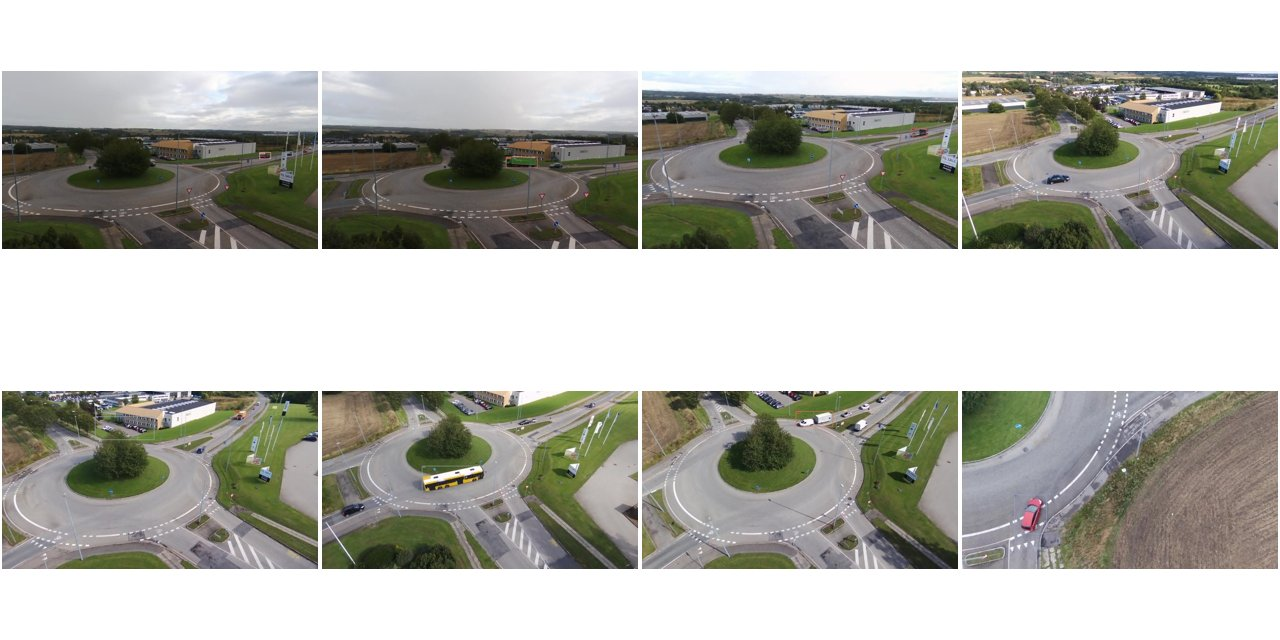

galerie : val


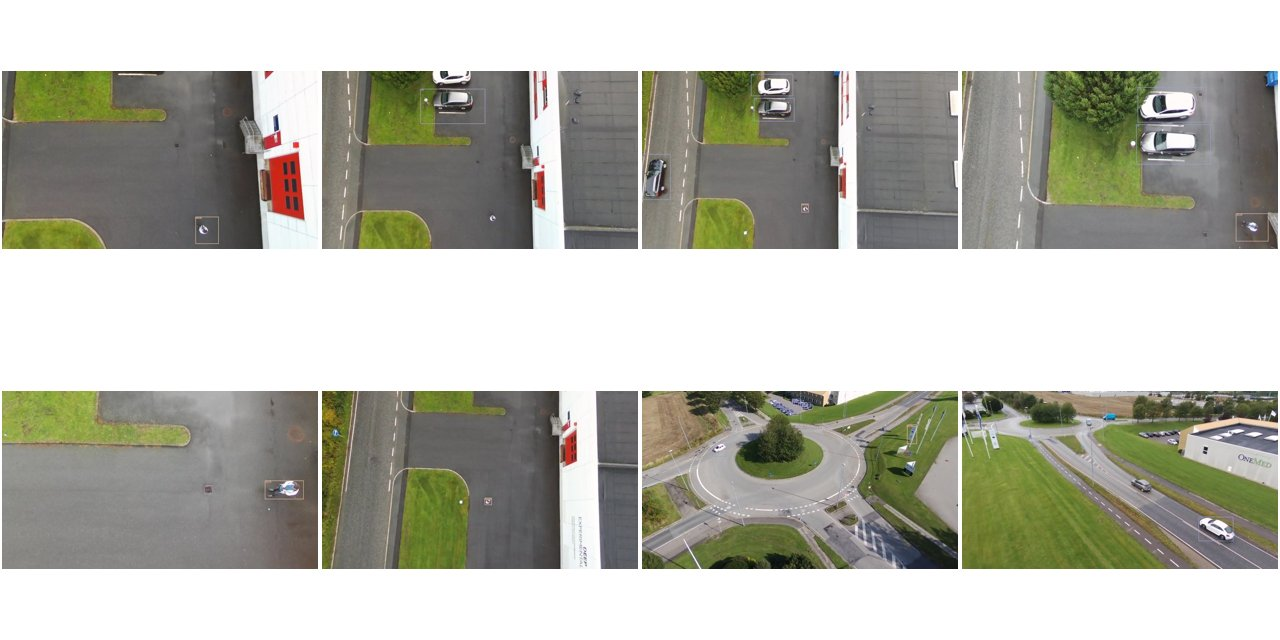

galerie : classes


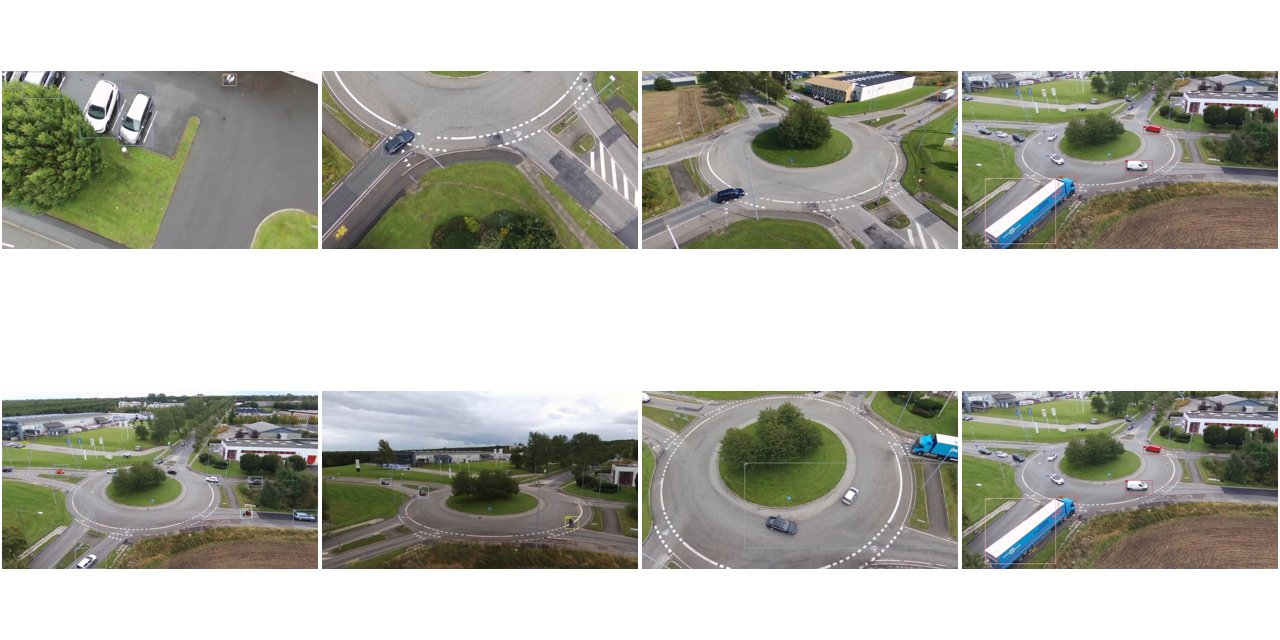

In [6]:
from yolo.data import datasets as D

rows = ["| classe | VOC | COCO |", "|---|---|---|"]
for c in D.DATASETS[DATASET].classes:
    m = [c if DATASET == f else D.MAPPINGS.get((DATASET, f), {}).get(c, "—")
         for f in ("voc", "coco")]
    rows.append(f"| {c} | {m[0]} | {m[1]} |")
display(Markdown("\n".join(rows)))
for g, sheet in STATS.get("galerie", {}).get("planches", {}).items():
    if g != "suspectes":
        print(f"galerie : {g}")
        display(Img(filename=str(Path(OUT, sheet))))

## Comptes et classes (T16.5)

Comptes par split (annotations, split entier), face aux effectifs officiels de la
fiche ; objets par classe et co-occurrence.

| partie | images | objets | difficult | images vides | objets/image (méd. / max) | petits < 32² à 416×416 | plus petits qu'une cellule | cibles perdues | images > 256 / > 1 024 |
|---|---|---|---|---|---|---|---|---|---|
| train | 27 880 | 114 237 | 0 | 2 | 3 / 52 | 81,7 % | 13x13 70,3 % · 26x26 35,1 % | 47,70 % | 0 / 0 |
| val | 4 943 | 17 740 | 0 | 1 | 3 / 56 | 67,9 % | 13x13 60,1 % · 26x26 31,5 % | 43,59 % | 0 / 0 |
| ensemble | 32 823 | 131 977 | 0 | 3 | 3 / 56 | 79,8 % | 13x13 69,0 % · 26x26 34,7 % | 47,15 % | 0 / 0 |

train : 27880 images, 114237 objets ; officiel 27880 / — : ok
val : 4943 images, 17740 objets ; officiel 4943 / — : ok


| classe | train : objets (images) | val : objets (images) | côté médian (px, letterbox) | petits |
|---|---|---|---|---|
| Human | 2 781 (2 397) | 2 371 (2 312) | 14 | 96 % |
| Car | 89 287 (25 309) | 13 294 (4 072) | 16 | 83 % |
| Truck | 8 791 (7 442) | 749 (602) | 33 | 49 % |
| Van | 9 062 (7 070) | 930 (730) | 24 | 71 % |
| Motorbike | 313 (306) | 5 (5) | 14 | 94 % |
| Bicycle | 1 011 (819) | 117 (115) | 14 | 96 % |
| Bus | 663 (618) | 66 (65) | 40 | 33 % |
| Trailer | 2 329 (1 854) | 208 (180) | 26 | 60 % |

Rapport classe la plus / la moins fréquente : 323.

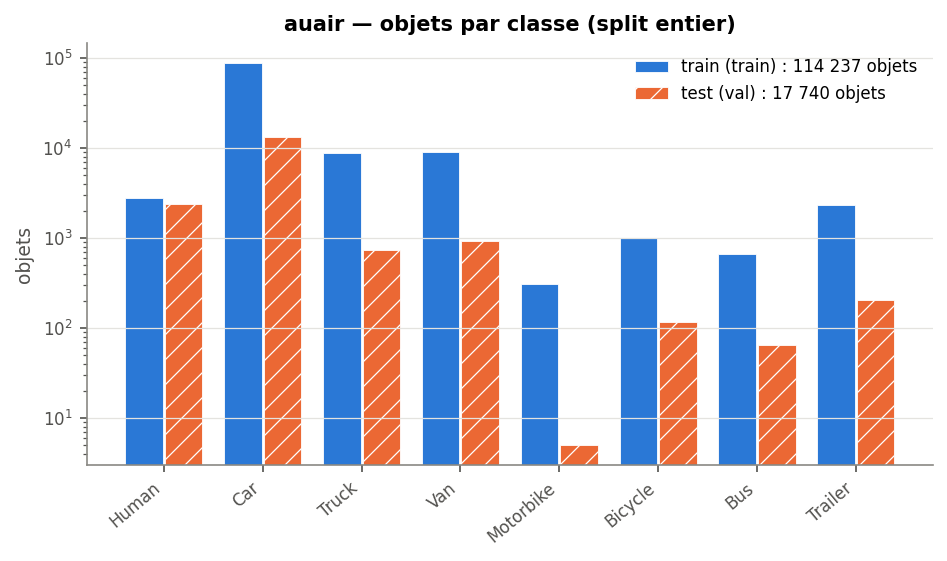

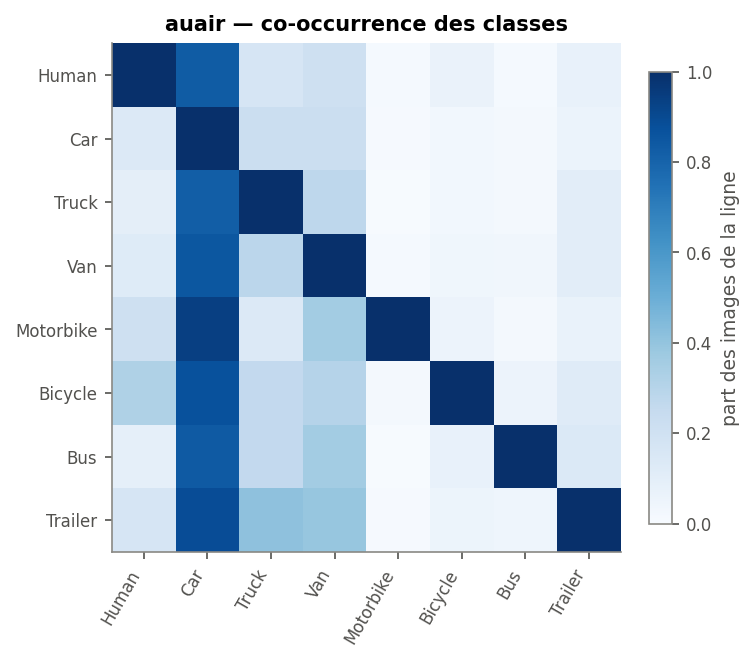

In [7]:
table(DS.md_synthese)
chk = DS.check_official(STATS)
for sp, i, o, (a, b), ok in chk:
    print(f"{sp} : {i} images, {o} objets ; officiel {a or '—'} / {b or '—'} : "
          f"{'ok' if ok else 'écart (voir les notes de la fiche)'}")
table(DS.md_classes)
show("classes")
show("cooccurrence")

## Géométrie des boîtes (T16.6)

Tailles en pixels d'origine et d'entrée (letterbox et stretch à `SIZE`), catégories
COCO avant et après redimensionnement, part des objets plus petits qu'une cellule de
chaque tête, centres des boîtes.

| repère | petits | moyens | grands | côté médian (px) | plus petits qu'une cellule | hauteur < 8 px |
|---|---|---|---|---|---|---|
| image d'origine | 11,8 % | 47,0 % | 41,3 % | 81 | — | — |
| letterbox 416×416 | 79,8 % | 19,6 % | 0,5 % | 18 | 13x13 69,0 % · 26x26 34,7 % | 22,8 % |
| stretch 416×416 | 66,3 % | 32,1 % | 1,6 % | 24 | 13x13 57,1 % · 26x26 24,5 % | 6,5 % |

131 977 objets non-difficult ; pas des têtes : 13x13 → 32 px, 26x26 → 16 px.

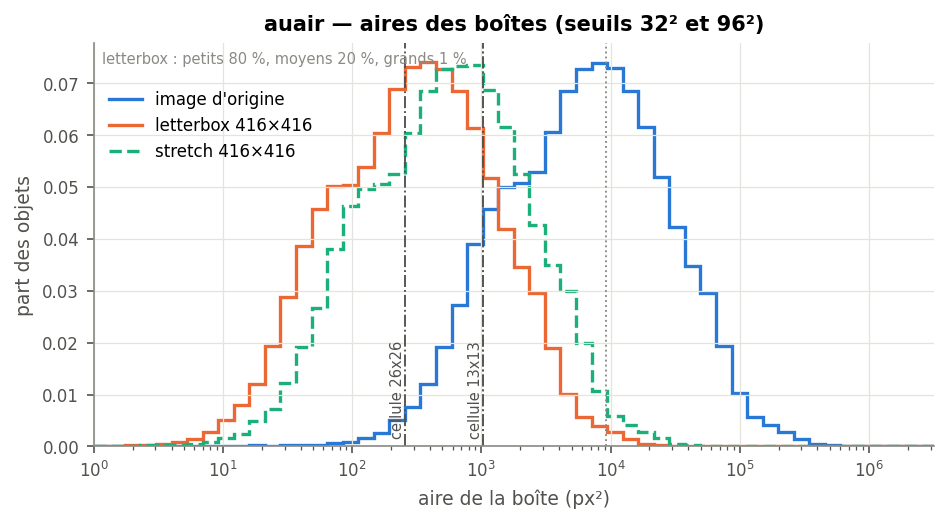

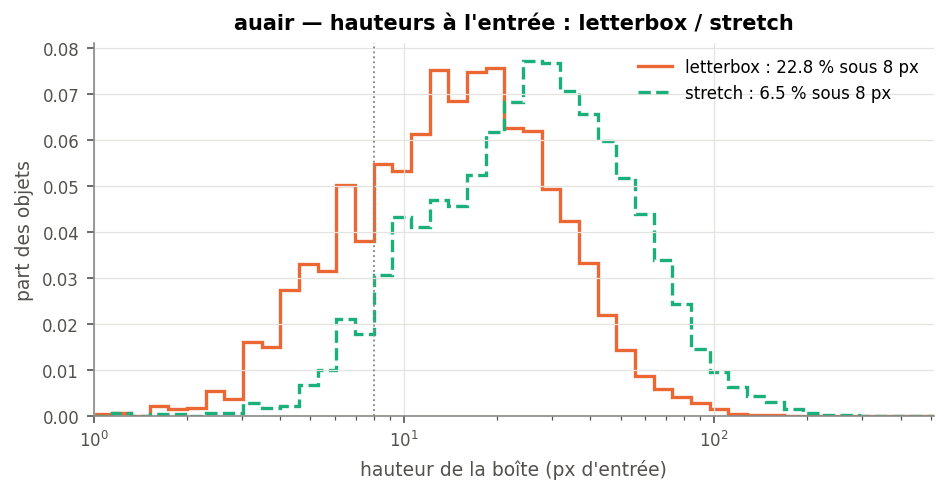

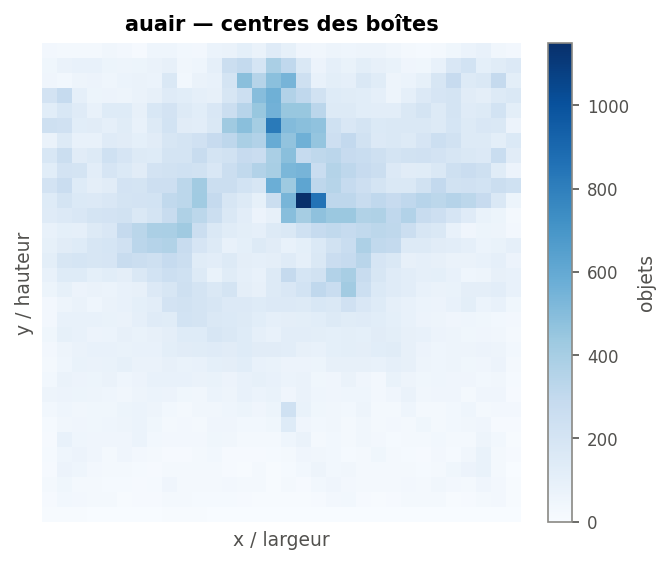

In [8]:
table(DS.md_geometrie)
show("tailles")
show("letterbox_stretch")
show("centres")

## Densité et collisions (T16.7)

Objets par image face aux 256 emplacements de `yolo_post` ; cibles perdues quand deux
objets tombent sur la même cellule et la même ancre (`build_targets`, ancres de `NET`).

| partie | objets/image moy. | méd. | max | > 256 / > 1 024 | cibles perdues | par tête (perdues / objets) | images touchées |
|---|---|---|---|---|---|---|---|
| train | 4,1 | 3 | 52 | 0 / 0 | 54 492 / 114 237 (47,70 %) | 13x13 : 0 / 202 · 26x26 : 87 / 59 630 | 14 808 |
| val | 3,6 | 3 | 56 | 0 / 0 | 7 733 / 17 740 (43,59 %) | 13x13 : 0 / 62 · 26x26 : 141 / 10 086 | 2 317 |
| ensemble | 4,0 | 3 | 56 | 0 / 0 | 62 225 / 131 977 (47,15 %) | 13x13 : 0 / 264 · 26x26 : 228 / 69 716 | 17 125 |

Ancres de `tiny-yolov3-coco` ; objets non-difficult, comme à l'entraînement.

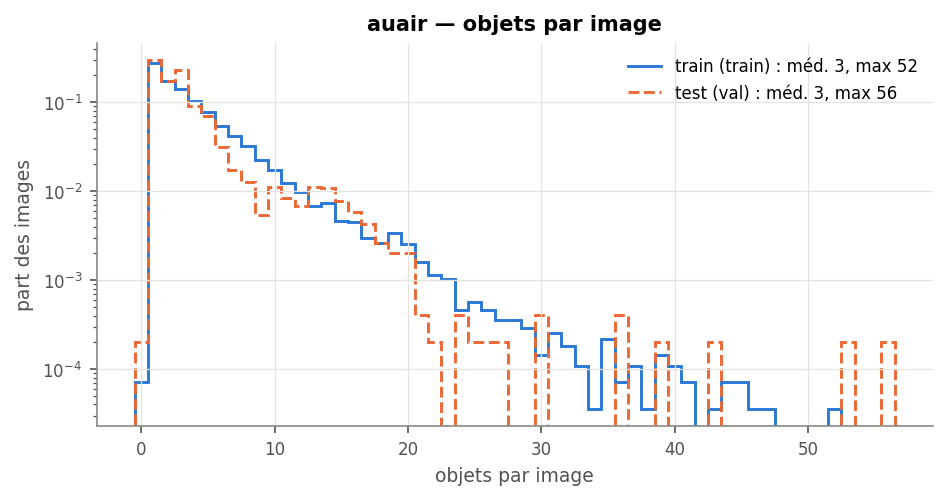

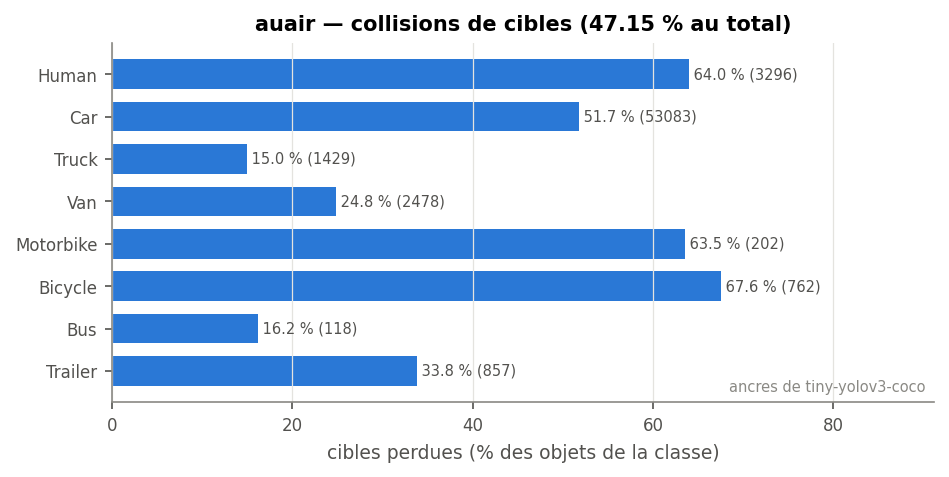

In [9]:
table(DS.md_densite)
show("densite")
show("collisions")

## Images (T16.8)

Résolutions sur le split entier (annotations) ; canaux, intensités et luminance sur
`SAMPLE` images par partie, face à VOC2007 test (échelles INT8 de M4).

| partie | résolutions (3 premières) | distinctes | pixels sur | canaux | moyenne par canal | écart type par canal | luminance moy. | niveaux 8 bits → INT8 |
|---|---|---|---|---|---|---|---|---|
| train | 1920×1080 (27 880) | 1 | 200 images | 3 | 124,5 / 124,7 / 109,0 | 51,5 / 49,0 / 60,2 | 122,8 | 256 → 128 |
| val | 1920×1080 (4 943) | 1 | 200 images | 3 | 123,0 / 125,2 / 102,2 | 47,9 / 46,2 / 57,9 | 121,9 | 256 → 128 |
| ensemble | 1920×1080 (32 823) | 1 | 200 images | 3 | 124,4 / 124,9 / 107,7 | 50,4 / 48,1 / 59,2 | 122,8 | 256 → 128 |

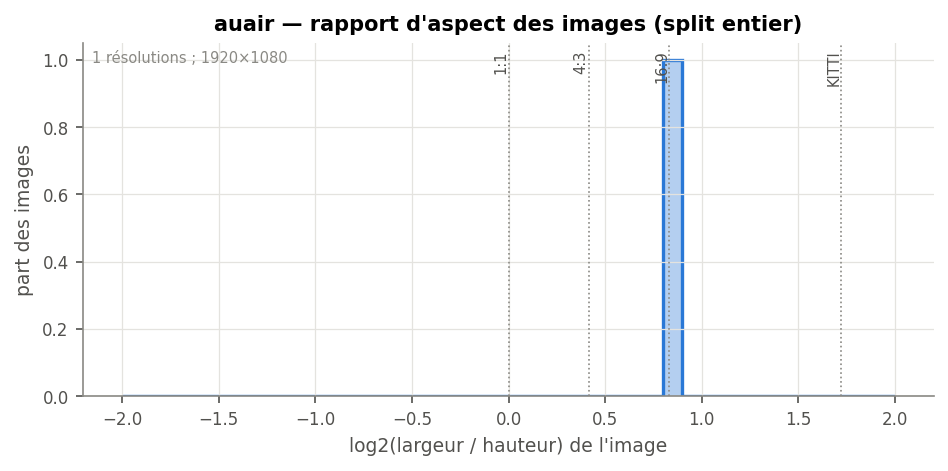

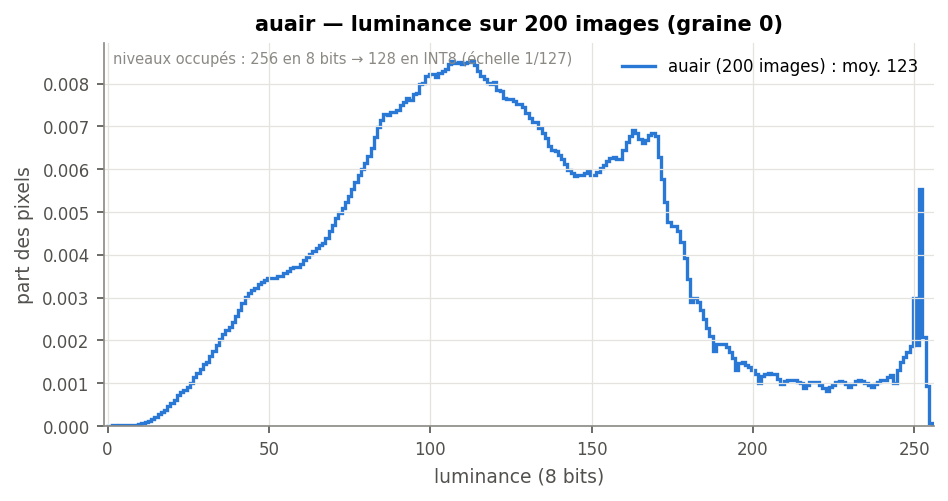

In [10]:
table(DS.md_images)
show("resolutions")
show("intensites")

## Ancres (T16.9)

Boîtes du groupe train en pixels d'entrée letterbox, ancres de la cfg, de VOC, de
COCO et du k-means (`tools/kmeans_anchors.py`, mêmes `--size` et `--seed`).

| ancres | w,h (px à 416×416) | IoU moyenne |
|---|---|---|
| VOC (tiny-yolov2-voc) | `35,38  109,141  212,364  301,164  532,337` | 0,2778 |
| VOC (tiny-yolov3-voc) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,4924 |
| COCO (tiny-yolov3-coco) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,4924 |
| cfg du jeu (tiny-yolov3-coco) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,4924 |
| k-means k = 5 (graine 0) | `9,6  19,14  34,23  57,37  110,67` | 0,6509 |
| k-means k = 6 (graine 0) | `9,6  18,13  29,21  48,28  63,46  124,72` | 0,6682 |

114 237 boîtes non-difficult du groupe train, letterbox 416×416.

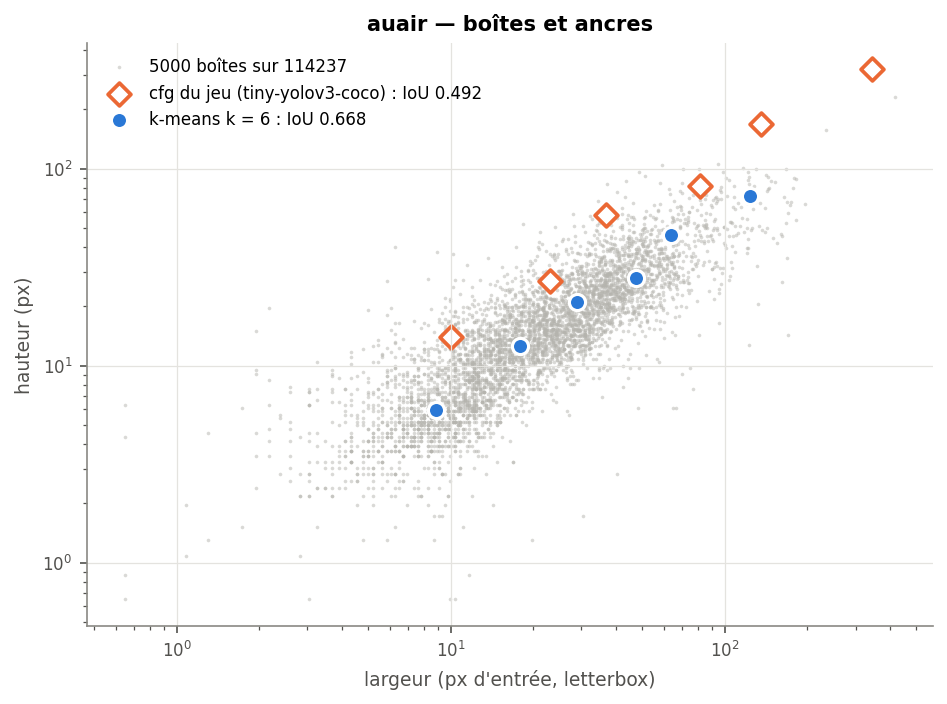

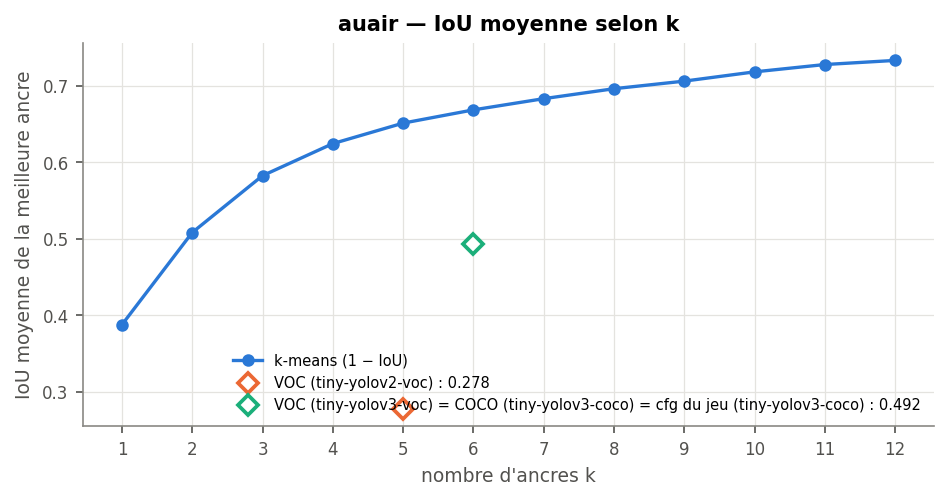

In [11]:
table(DS.md_ancres)
show("ancres")
show("ancres_k")

## Qualité des annotations (T16.10)

Boîtes retirées ou rognées par le chargeur, dégénérées, doublons, régions retirées ;
l'analyse signale, elle ne corrige pas (une correction passe par M11).

| partie | retirées (make_sample) | rognées | côté < 2 px (orig. / entrée) | doublons (IoU > 0,95) | régions retirées par le chargeur |
|---|---|---|---|---|---|
| train | 45 | 0 | 0 / 872 | 0 | — |
| val | 9 | 0 | 0 / 107 | 0 | — |
| ensemble | 54 | 0 | 0 / 979 | 0 | — |

frame_20190906150731_x_0005162 : score 5 (retirées 5, rognées 0, dégénérées 0, doublons 0)
frame_20190905103112_x_0003055 : score 3 (retirées 3, rognées 0, dégénérées 0, doublons 0)
frame_20190905103112_x_0004422 : score 3 (retirées 3, rognées 0, dégénérées 0, doublons 0)
frame_20190906150731_x_0000818 : score 3 (retirées 3, rognées 0, dégénérées 0, doublons 0)
frame_20190829091111_x_0002788 : score 2 (retirées 2, rognées 0, dégénérées 0, doublons 0)
frame_20190905103112_x_0001711 : score 2 (retirées 2, rognées 0, dégénérées 0, doublons 0)
frame_20190905103112_x_0004938 : score 2 (retirées 2, rognées 0, dégénérées 0, doublons 0)
frame_20190906150731_x_0001617 : score 2 (retirées 2, rognées 0, dégénérées 0, doublons 0)
frame_20190829091111_x_0000489 : score 1 (retirées 1, rognées 0, dégénérées 0, doublons 0)
frame_20190905091750_xx_0000130 : score 1 (retirées 1, rognées 0, dégénérées 0, doublons 0)


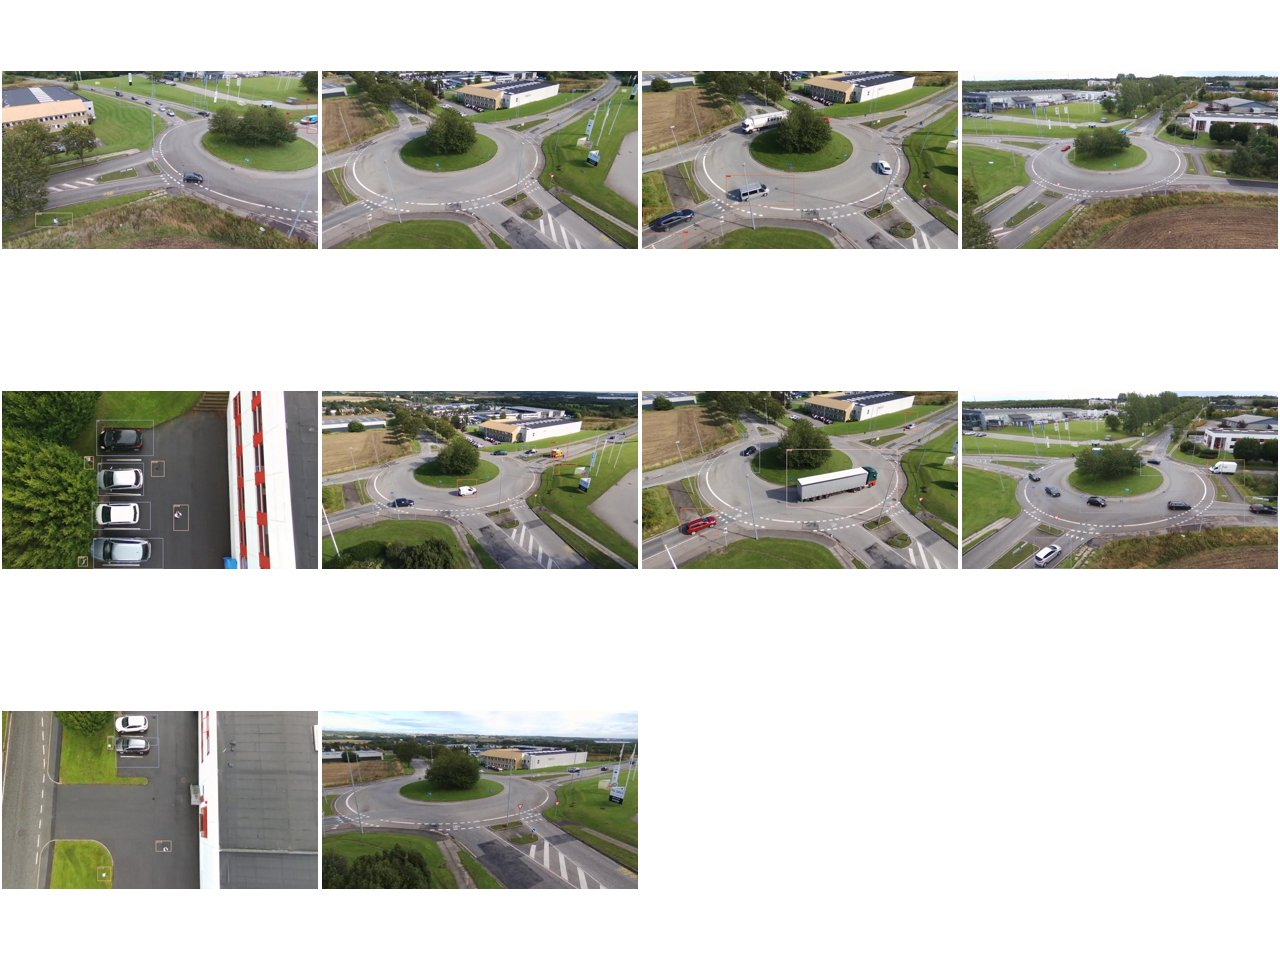

In [12]:
table(DS.md_qualite)
sus = DS.whole(STATS).get("qualite", {}).get("suspects", [])
for d in sus:
    print(f"{d['id']} : score {d['score']} (retirées {d['retirées']}, rognées "
          f"{d['rognées']}, dégénérées {d['dégénérées']}, doublons {d['doublons']})")
sheet = STATS.get("galerie", {}).get("planches", {}).get("suspectes")
if sheet:
    display(Img(filename=str(Path(OUT, sheet))))

## Écart entre splits et couverture hors domaine (T16.11)

Distance en variation totale entre train et test, par grandeur ; part des objets qui
ont une classe VOC ou COCO (ce qu'évaluent les notebooks hors domaine de T14.5).

| grandeur (train ↔ test) | variation totale |
|---|---|
| classes | 0,109 |
| area_in | 0,150 |
| w_in | 0,158 |
| h_in | 0,128 |
| aspect | 0,064 |
| per_image | 0,125 |

| split | classes du modèle | objets couverts | part | évalués (non-difficult) |
|---|---|---|---|---|
| train | VOC | 103 117 | 90,3 % | 103 117 |
| train | COCO | 111 908 | 98,0 % | 111 908 |
| val | VOC | 16 783 | 94,6 % | 16 783 |
| val | COCO | 17 532 | 98,8 % | 17 532 |

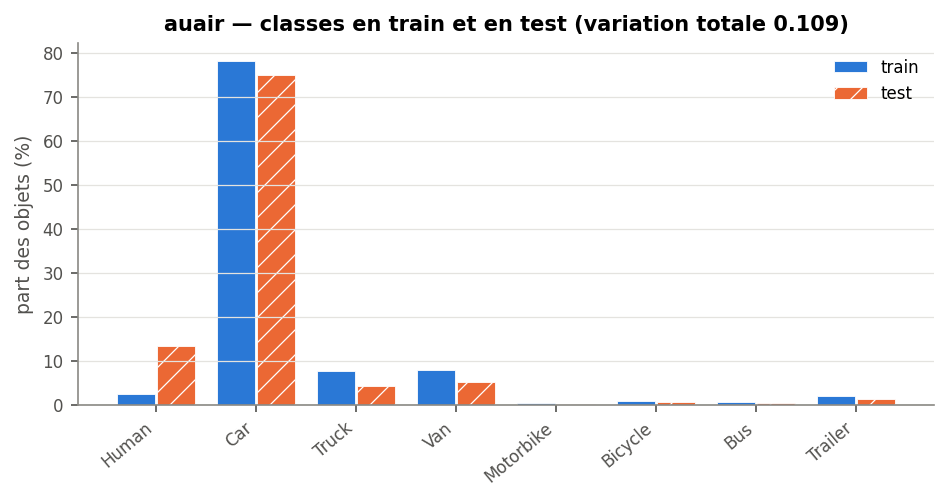

In [13]:
table(DS.md_ecart)
show("ecart")

## Question propre au jeu

Que reste-t-il des objets d'une trame 1920×1080 réduite à 416, classe par classe ? (renvoi : T18.1)

In [14]:
g = DS.whole(STATS)["geometrie"][STATS["params"]["resize"]]
print("plus petits qu'une cellule : " + ", ".join(f"{k} {100 * v:.1f} %"
                                                   for k, v in g["fit_cell"].items()))
print(f"hauteur < 8 px : {100 * g['h_under']['8']:.1f} %")
display(Markdown(DS.md_par_classe(STATS)))

plus petits qu'une cellule : 13x13 69.0 %, 26x26 34.7 %
hauteur < 8 px : 22.8 %


| classe | objets (test, non-difficult) | part | côté médian (px) | petits | cibles perdues |
|---|---|---|---|---|---|
| Human | 2 371 | 13,4 % | 18 | 93 % | 44,37 % |
| Car | 13 294 | 74,9 % | 19 | 64 % | 46,02 % |
| Truck | 749 | 4,2 % | 30 | 56 % | 13,62 % |
| Van | 930 | 5,2 % | 23 | 64 % | 32,69 % |
| Motorbike | 5 | 0,0 % | 11 | 100 % | 60,00 % |
| Bicycle | 117 | 0,7 % | 12 | 89 % | 64,96 % |
| Bus | 66 | 0,4 % | 17 | 80 % | 50,00 % |
| Trailer | 208 | 1,2 % | 27 | 55 % | 21,63 % |

## Résumé

In [15]:
table(DS.md_synthese)
print(f"sorties : {OUT}/ (stats.json, stats.md, figures/, galerie/) ; "
      f"révision {TRACE['rev']}")
print("commandes équivalentes :")
for c in C.HISTORY:
    print("  " + c)

| partie | images | objets | difficult | images vides | objets/image (méd. / max) | petits < 32² à 416×416 | plus petits qu'une cellule | cibles perdues | images > 256 / > 1 024 |
|---|---|---|---|---|---|---|---|---|---|
| train | 27 880 | 114 237 | 0 | 2 | 3 / 52 | 81,7 % | 13x13 70,3 % · 26x26 35,1 % | 47,70 % | 0 / 0 |
| val | 4 943 | 17 740 | 0 | 1 | 3 / 56 | 67,9 % | 13x13 60,1 % · 26x26 31,5 % | 43,59 % | 0 / 0 |
| ensemble | 32 823 | 131 977 | 0 | 3 | 3 / 56 | 79,8 % | 13x13 69,0 % · 26x26 34,7 % | 47,15 % | 0 / 0 |

sorties : build/notebooks/auair/stats/ (stats.json, stats.md, figures/, galerie/) ; révision 7738bf9
commandes équivalentes :
  python tools/data_stats.py --dataset auair --size 416 --resize letterbox --net tiny-yolov3-coco --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/auair/stats
